<a href="https://colab.research.google.com/github/SahanaV96111/DAV/blob/main/Lab6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA

In [5]:
df = pd.read_csv("/content/archive.zip")

In [3]:
print("First five rows:")
print(df.head())
print("\nDataset shape:")
print(df.shape)

First five rows:
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  
0      9.4        5  
1      9.8        5  
2  

In [4]:
print("\ncolumn names")
print(df.columns)

print("\nMissing values")
print(df.isnull().sum())


column names
Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='object')

Missing values
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64


In [6]:
x = df.drop("quality", axis=1)
y = df["quality"]
normalizer = MinMaxScaler()
X_normalized = normalizer.fit_transform(x)
print("\nNormalised data(first 5 rows):")
print(pd.DataFrame(X_normalized, columns=x.columns).head().round(3))


Normalised data(first 5 rows):
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0          0.248             0.397         0.00           0.068      0.107   
1          0.283             0.521         0.00           0.116      0.144   
2          0.283             0.438         0.04           0.096      0.134   
3          0.584             0.110         0.56           0.068      0.105   
4          0.248             0.397         0.00           0.068      0.107   

   free sulfur dioxide  total sulfur dioxide  density     pH  sulphates  \
0                0.141                 0.099    0.568  0.606      0.138   
1                0.338                 0.216    0.494  0.362      0.210   
2                0.197                 0.170    0.509  0.409      0.192   
3                0.225                 0.191    0.582  0.331      0.150   
4                0.141                 0.099    0.568  0.606      0.138   

   alcohol  
0    0.154  
1    0.215  
2    0.21

In [9]:
scaler = StandardScaler()
X_standardized = scaler.fit_transform(x)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_standardized)
print("\nPCA output(first 5 rows):")
print(pd.DataFrame(X_pca, columns=["PC1", "PC2"]).head().round(3))
print("\nOriginal number of features:", x.shape[1])
print("Reduced number of features:", X_pca.shape[1])


PCA output(first 5 rows):
     PC1    PC2
0 -1.620  0.451
1 -0.799  1.857
2 -0.748  0.882
3  2.358 -0.270
4 -1.620  0.451

Original number of features: 11
Reduced number of features: 2



Variance explained by each component:
[0.2817 0.1751]

Total variance explained: 45.68 %


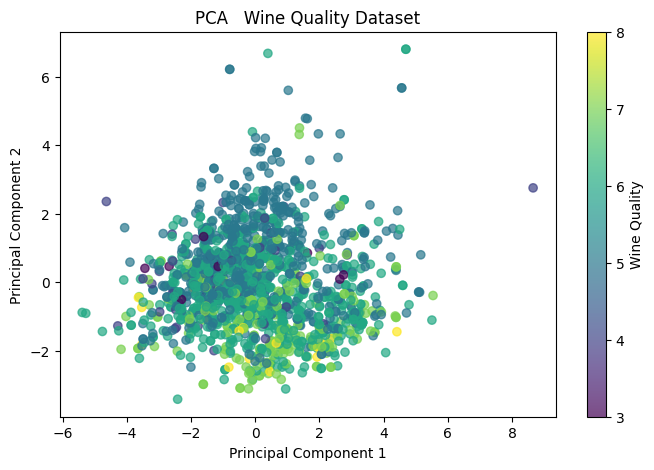

In [10]:
print("\nVariance explained by each component:")
print(pca.explained_variance_ratio_.round(4))

print("\nTotal variance explained:",
      round(sum(pca.explained_variance_ratio_) * 100, 2), "%")

plt.figure(figsize=(8, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1],
            c=y, cmap="viridis", alpha=0.7)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.title("PCA   Wine Quality Dataset")
plt.colorbar(label="Wine Quality")
plt.show()